# Theoretisches von Chatty

### Umgang mit kategorischen Variablen

Das ist bei deinem Datensatz besonders relevant.

KNN benötigt numerische Werte, um Distanzen berechnen zu können.

Du musst also deine kategorischen Variablen entsprechend encodieren.

A) Ordinal Categories

Beispielsweise:

* Primary School
* High School
* Graduate
* Masters
* Phd

Hier besteht eine natürliche Reihenfolge.

Du kannst deshalb einen OrdinalEncoder verwenden.

Das hat einen Vorteil: Die Reihenfolge der Kategorien bleibt erhalten.

B) Nominal Categories

Beispielsweise:

* Gender
* Major Discipline
* Company Type
* City

Hier existiert keine natürliche Reihenfolge.

Du solltest deshalb keinen OrdinalEncoder verwenden.

Stattdessen bietet sich One-Hot-Encoding an.

In [3]:
## SciKit Learn Package herunterladen:
#bei erster ausführung auskommentieren
#%pip install scikit-learn

## 1. Imports und Daten laden

In [4]:
import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OrdinalEncoder, OneHotEncoder, MinMaxScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (accuracy_score, classification_report,
                             confusion_matrix, ConfusionMatrixDisplay, roc_auc_score)

df = pd.read_pickle("customer_train_typed.pkl")
print(df.shape)
df.head()

(19158, 14)


/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/pandas/io/formats/format.py:1486: RuntimeWarning: overflow encountered in cast
  has_large_values = (abs_vals > 1e6).any()


,student_id,city,city_development_index,gender,relevant_experience,enrolled_university,education_level,major_discipline,experience,company_size,company_type,last_new_job,training_hours,job_change
0,8949,city_103,0.919922,Male,True,no_enrollment,Graduate,STEM,>20,NaN,NaN,1,36,True
1,29725,city_40,0.775879,Male,False,no_enrollment,Graduate,STEM,15,50-99,Pvt Ltd,>4,47,False
2,11561,city_21,0.624023,NaN,False,Full time course,Graduate,STEM,5,NaN,NaN,never,83,False
3,33241,city_115,0.789062,NaN,False,NaN,Graduate,Business Degree,<1,NaN,Pvt Ltd,never,52,True
4,666,city_162,0.767090,Male,True,no_enrollment,Masters,STEM,>20,50-99,Funded Startup,4,8,False


In [5]:
# exploration der Zielvariablen:
print(df["job_change"].value_counts(normalize=True))
print(df.isna().sum())

job_change
False    0.750652
True     0.249348
Name: proportion, dtype: float64
student_id                   0
city                         0
city_development_index       0
gender                    4508
relevant_experience          0
enrolled_university        386
education_level            460
major_discipline          2813
experience                  65
company_size              5938
company_type              6140
last_new_job               423
training_hours               0
job_change                   0
dtype: int64


Warum? KNN reagiert empfindlich auf unausgewogene Klassen. Bei 75 % False würde ein Modell, das immer False sagt, schon 75 % Accuracy erreichen. Das ist deine Baseline: Ein sinnvolles Modell muss darüber liegen, und Accuracy allein ist hier eine schwache Kennzahl. Wir schauen deshalb zusätzlich auf Precision, Recall und ROC-AUC.

In [6]:
# Irrelevante bzw. problematische Spalten entfernen
df_model = df.drop(columns=["student_id", "city"])

X = df_model.drop(columns="job_change").copy()
y = df_model["job_change"].astype(int)       # True/False -> 1/0

# Datentypen für sklearn vereinheitlichen
X["relevant_experience"] = X["relevant_experience"].astype(int)
X["city_development_index"] = X["city_development_index"].astype("float64")  # float16 -> float64
for col in X.select_dtypes("category").columns:
    X[col] = X[col].astype(object)           # sklearn-Imputer kommen mit object besser klar

Erläuterungen:

- student_id ist nur eine ID. Sie hat keinen Informationsgehalt und würde bei KNN die Distanzen verfälschen.
- city hat 123 Ausprägungen. One-Hot-Encoding würde 123 Spalten erzeugen und den Raum aufblähen (Fluch der Dimensionalität). city_development_index enthält die relevante Information schon, das hattest du in deiner Cramér’s-V-Analyse ebenfalls so entschieden.
- float16 kann bei Berechnungen ungenau sein, deshalb die Umwandlung in float64.

## 2. Spalten nach Typ gruppieren

Wichtig weil: weil du bei KNN nicht alle Variablen gleich behandeln kannst. Du musst dem Preprocessing zunächst mitteilen, welche Art von Daten in welcher Spalte steckt, damit anschließend die passenden Methoden zur Verarbeitung angewendet werden können.




In [8]:
ordinal_cols = ["education_level", "experience", "company_size", "last_new_job"]

# Hier definierst du eine Liste mit allen Spalten, die ordinale Kategorien enthalten.

# Ordinale Kategorien sind Kategorien, zwischen denen eine natürliche Reihenfolge besteht.

In [ ]:
ordinal_order = [
    ["Primary School", "High School", "Graduate", "Masters", "Phd"],
    ["<1"] + [str(i) for i in range(1, 21)] + [">20"],
    ["<10", "10-49", "50-99", "100-499", "500-999", "1000-4999", "5000-9999", "10000+"],
    ["never", "1", "2", "3", "4", ">4"],
]
# Hier werden die Reihenfolgen der oridnal_cols festgelegt.

nominal_cols = ["gender", "enrolled_university", "major_discipline", "company_type"]
numeric_cols = ["city_development_index", "training_hours"]
binary_cols = ["relevat_experience"]

## (Logik überprüfen!!)

## 3. Preprocessing Pipeline

Hier darauf achten, das wir hier mit dem Simpleimputer eine automatische impuation von Missing Values erreichen. Wenn wir vorher die **Imputation auf dem Datensatz** erreich, daann brauchen wir das nicht mehr und **müssen diesen code ändern!**

In [13]:
ordinal_pipe = Pipeline([
    ("enc", OrdinalEncoder(categories=ordinal_order,
                           handle_unknown="use_encoded_value", unknown_value=np.nan)),
    ("imp", SimpleImputer(strategy="median", add_indicator=True)),
    ("scale", MinMaxScaler()),
])

nominal_pipe = Pipeline([
    ("imp", SimpleImputer(strategy="constant", fill_value="missing")),
    ("onehot", OneHotEncoder(handle_unknown="ignore")),
])

preprocessor = ColumnTransformer([
    ("ord", ordinal_pipe, ordinal_cols),
    ("nom", nominal_pipe, nominal_cols),
    ("num", MinMaxScaler(), numeric_cols),
])

- Skalierung ist bei KNN Pflicht. training_hours reicht bis 336, city_development_index nur von 0 bis 1. Ohne Skalierung würde training_hours die Distanz praktisch alleine bestimmen. MinMaxScaler bringt alles auf 0 bis 1 und passt damit zu den One-Hot-Spalten (ebenfalls 0/1).
- Fehlende Werte (nominal): Ich ersetze sie durch eine eigene Kategorie "missing". Dass z. B. company_type fehlt, ist oft selbst informativ (etwa weil jemand gerade nicht angestellt ist). Würde man mit dem häufigsten Wert auffüllen, ginge diese Information verloren.
- Fehlende Werte (ordinal): Median-Imputation plus add_indicator=True. Dadurch entsteht pro betroffener Spalte eine zusätzliche 0/1-Spalte, die markiert, wo ursprünglich ein Wert fehlte.
- Pipeline und Data Leakage: Imputer, Encoder und Scaler lernen ihre Parameter (Median, Min/Max, Kategorien) nur aus den Trainingsdaten. Packt man sie in eine Pipeline, passiert das automatisch, auch innerhalb der Cross-Validation. Würdest du vorab auf dem gesamten Datensatz skalieren, flössen Informationen aus den Testdaten ins Training (Data Leakage).

## 4. Datenset splitten in Train und Test Data
-> Dabei muss verteilung der target Variable bei 75/25 bleiben und reporduzierbar random ausgewählt werden

In [14]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

- test_size=0.2: 80 % zum Trainieren, 20 % zum finalen Testen. Das Testset rührst du erst am Ende an.
- stratify=y: In Train und Test bleibt der Anteil von 25 % True erhalten. Bei unausgewogenen Klassen ist das wichtig.
- random_state=42: macht die Aufteilung reproduzierbar.

## 5. Basemodel mit k = 5

Accuracy: 0.7533924843423799
              precision    recall  f1-score   support

           0       0.82      0.86      0.84      2877
           1       0.51      0.44      0.47       955

    accuracy                           0.75      3832
   macro avg       0.66      0.65      0.65      3832
weighted avg       0.74      0.75      0.75      3832



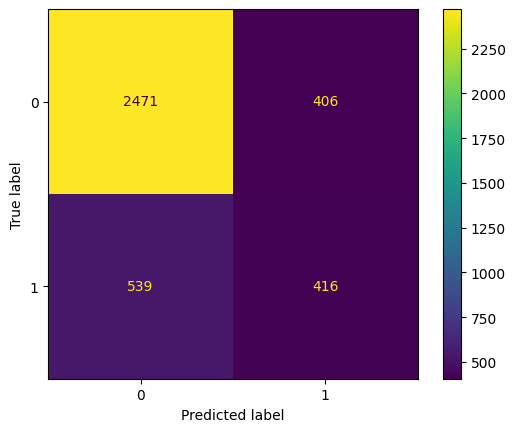

In [15]:
knn_pipe = Pipeline([
    ("pre", preprocessor),
    ("knn", KNeighborsClassifier(n_neighbors=5)),
])

knn_pipe.fit(X_train, y_train)
y_pred = knn_pipe.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred)

Wie KNN funktioniert: Beim Training „lernt“ KNN nichts im klassischen Sinn, es speichert nur die Trainingsdaten. Bei einer neuen Person sucht es die k ähnlichsten Personen im Trainingsset (kleinste Distanz) und lässt sie per Mehrheit abstimmen.

Ergebnis bei mir: Accuracy ≈ 0,747. Das liegt unter der 75-%-Baseline, und der Recall der Klasse True beträgt nur 0,41. Das Modell erkennt also weniger als die Hälfte der Wechselwilligen. k = 5 ist zu klein: Das Modell reagiert zu stark auf Rauschen (Overfitting).

## 6: Hyperparameter-Tuning mit Cross-Validation

- n_neighbors ist der wichtigste Hebel. Kleine k führen zu einer zackigen, rauschanfälligen Entscheidungsgrenze (hohe Varianz), große k zu einer glatten (hoher Bias).
- weights="distance" gewichtet nähere Nachbarn stärker.
- p wählt die Distanzmetrik. Manhattan funktioniert bei vielen One-Hot-Spalten oft besser.
- 5-fach Cross-Validation: Die Trainingsdaten werden fünfmal in Trainings- und Validierungsteil zerlegt. So wählst du Parameter, ohne das Testset zu benutzen.
- scoring="roc_auc" statt Accuracy, weil ROC-AUC bei unausgewogenen Klassen aussagekräftiger ist. Es misst, wie gut das Modell die Klassen über alle Schwellenwerte hinweg trennt.

In [16]:
param_grid = {
    "knn__n_neighbors": [5, 15, 31, 51, 75],
    "knn__weights": ["uniform", "distance"],
    "knn__p": [1, 2],          # 1 = Manhattan-, 2 = euklidische Distanz
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

grid = GridSearchCV(knn_pipe, param_grid, cv=cv, scoring="roc_auc", n_jobs=-1)
grid.fit(X_train, y_train)

print("Beste Parameter:", grid.best_params_)
print("Bester CV-ROC-AUC:", grid.best_score_)

Beste Parameter: {'knn__n_neighbors': 75, 'knn__p': 1, 'knn__weights': 'uniform'}
Bester CV-ROC-AUC: 0.7748147162784955


## 7. FInale Evaluation auf TEstset

Test-ROC-AUC: 0.7888128813645687
              precision    recall  f1-score   support

           0       0.81      0.91      0.86      2877
           1       0.57      0.38      0.46       955

    accuracy                           0.77      3832
   macro avg       0.69      0.64      0.66      3832
weighted avg       0.75      0.77      0.76      3832



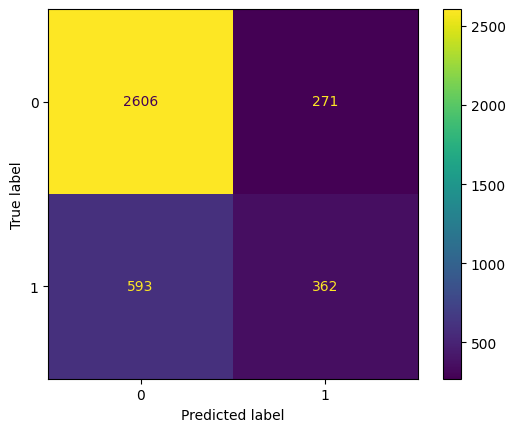

In [17]:
best_model = grid.best_estimator_

y_proba = best_model.predict_proba(X_test)[:, 1]
y_pred_best = best_model.predict(X_test)

print("Test-ROC-AUC:", roc_auc_score(y_test, y_proba))
print(classification_report(y_test, y_pred_best))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred_best)

ist besser geworden!

## 8. Schwellenwert anpassen


Standardmäßig sagt das Modell True, wenn die Wahrscheinlichkeit ≥ 0,5 ist. Bei nur 25 % positiven Fällen ist das oft zu streng.

In [18]:
threshold = 0.3
y_pred_thr = (y_proba >= threshold).astype(int)

print(classification_report(y_test, y_pred_thr))

              precision    recall  f1-score   support

           0       0.90      0.76      0.82      2877
           1       0.51      0.74      0.60       955

    accuracy                           0.76      3832
   macro avg       0.70      0.75      0.71      3832
weighted avg       0.80      0.76      0.77      3832



Welcher Schwellenwert richtig ist, hängt von deinem Ziel ab: Willst du möglichst viele Wechselwillige finden (Recall hoch, mehr Fehlalarme), oder lieber wenige, aber sichere Treffer (Precision hoch)? Das ist eine inhaltliche Entscheidung, die du in deiner Arbeit begründen solltest. KNN selbst hat keinen class_weight-Parameter, der Schwellenwert ist hier der einfachste Weg